# 01 · Data and missing values

**Goal.** Build the matrices used in the rest of the study and describe where the imputed values are.

The workbook `data/raw/ilia_2026_resultados_consolidados.xlsx` has three sheets with the same 126 subindicators for 20 countries:

| sheet | content |
|---|---|
| `bruto` | raw values, with **empty cells where no data exists** |
| `normalizado` | intermediate step |
| `final` | 0–100 scores, **with the empty cells imputed** (MICE, Bayesian ridge, auxiliary predictors such as GDP, population, 10-year GDP growth) |

A `final` value is imputed exactly when the same cell in `bruto` is empty. Masking `final` with the `bruto` gaps gives the real-data-only scores.

Two data sources come out of this notebook, and **all 20 countries are kept in both**:

* **A — real data only:** the masked scores, keeping the subindicators with no gaps (a complete table is needed for PCA).
* **I — imputed:** the full `final` sheet.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from ilia_explore import data as D, pruning as P, pca as PC, clustering as CL, plots as PL, pipeline as PP

PL.setup_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.precision", 3)

## Load and check the workbook

In [2]:
sheets = D.load_sheets()          # raises if the three sheets are not aligned row by row
codebook = D.build_codebook(sheets)
final = D.wide_final(sheets, codebook)
masked = D.wide_masked(sheets, codebook)
D.check_mask(final, masked)       # every observed cell equals its final value

D.PROCESSED.mkdir(parents=True, exist_ok=True)
codebook.to_csv(D.PROCESSED / "codebook.csv")
masked.to_csv(D.PROCESSED / "final_masked_wide.csv")
final.to_csv(D.PROCESSED / "final_imputed_wide.csv")
print(f"{final.shape[0]} subindicators x {final.shape[1]} countries; "
      f"{int(masked.isna().sum().sum())} imputed cells ({masked.isna().mean().mean():.1%})")
codebook.head(8)

126 subindicators x 20 countries; 141 imputed cells (5.6%)


,dim_code,subdim_code,dim,subdim,indicador,subindicador,n_observed,n_imputed,n_unique_observed,categorical,imputed_countries
code,,,,,,,,,,,
FH.INF.01,FH,INF,FH,Infraestructura,Conectividad,Cobertura 5G,19,1,13,False,CUB
FH.INF.02,FH,INF,FH,Infraestructura,Conectividad,Cobertura Redes Móviles (%) Mínimo 3G,20,0,16,False,
FH.INF.03,FH,INF,FH,Infraestructura,Conectividad,Velocidad Descarga Móvil,15,5,15,False,"CUB, JAM, DOM, TTO, URY"
FH.INF.04,FH,INF,FH,Infraestructura,Conectividad,Velocidad de Descarga Banda Ancha Fija (Mbps),20,0,20,False,
FH.INF.05,FH,INF,FH,Infraestructura,Conectividad,Latencia Fija (ms),20,0,8,False,
FH.INF.06,FH,INF,FH,Infraestructura,Conectividad,Latencia Móvil (ms),15,5,8,False,"CUB, JAM, DOM, TTO, URY"
FH.INF.07,FH,INF,FH,Infraestructura,Conectividad,Suscripciones Activas de Banda Ancha Móvil (cada 100 personas),20,0,20,False,
FH.INF.08,FH,INF,FH,Infraestructura,Conectividad,Suscripciones Activas de Banda Ancha Fija (cada 100 personas),20,0,20,False,


Each subindicator gets a short code `<DIM>.<SUBDIM>.<nn>` used in every figure; `data/processed/codebook.csv` maps codes to names.
Dimensions: **FH** enabling factors, **GOB** governance, **IDA** R&D and adoption.

## The two matrices

In [3]:
A = D.matrix_A(masked)
I = D.matrix_I(final)
A.to_csv(D.PROCESSED / "A-full.csv")
I.to_csv(D.PROCESSED / "I-full.csv")
print("A-full:", A.shape, "   I-full:", I.shape)

by_dim = codebook.groupby("dim_code").agg(
    subindicators=("n_imputed", "size"),
    with_gaps=("n_imputed", lambda s: int((s > 0).sum())),
    imputed_cells=("n_imputed", "sum"),
    categorical=("categorical", "sum"),
)
by_dim["in_A"] = by_dim["subindicators"] - by_dim["with_gaps"]
by_dim["share_of_A"] = by_dim["in_A"] / by_dim["in_A"].sum()
by_dim["share_of_I"] = by_dim["subindicators"] / by_dim["subindicators"].sum()
D.RESULTS.mkdir(parents=True, exist_ok=True)
by_dim.to_csv(D.RESULTS / "missingness_by_dimension.csv")
by_dim

A-full: (20, 86)    I-full: (20, 126)


,subindicators,with_gaps,imputed_cells,categorical,in_A,share_of_A,share_of_I
dim_code,,,,,,,
FH,49,23,84,1,26,0.302,0.389
GOB,37,3,8,24,34,0.395,0.294
IDA,40,14,49,0,26,0.302,0.317


**Composition matters.** Most gaps are in FH and IDA, so A over-represents governance compared with I. Many governance subindicators are also **categorical** (2–3 distinct values, typically 0/50/100: whether a strategy, budget or institution exists). They are kept as they are; with standardization they behave as yes/no contrasts in PCA.

## Where the gaps are

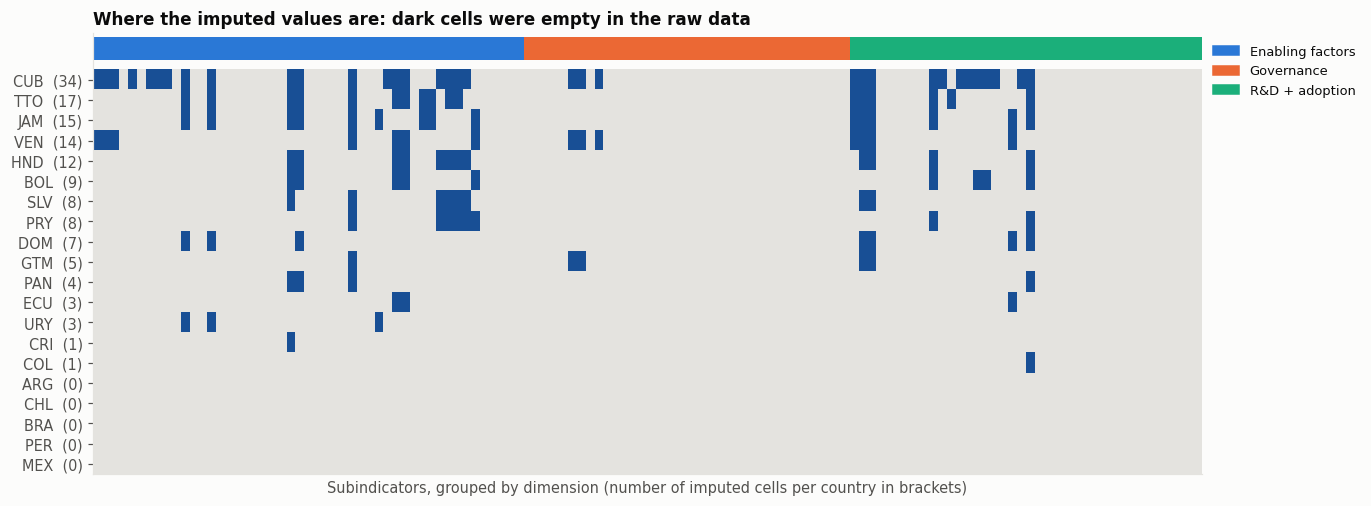

In [4]:
fig = PL.missingness_map(masked, codebook); PL.save(fig, "01_missingness_map"); plt.show()

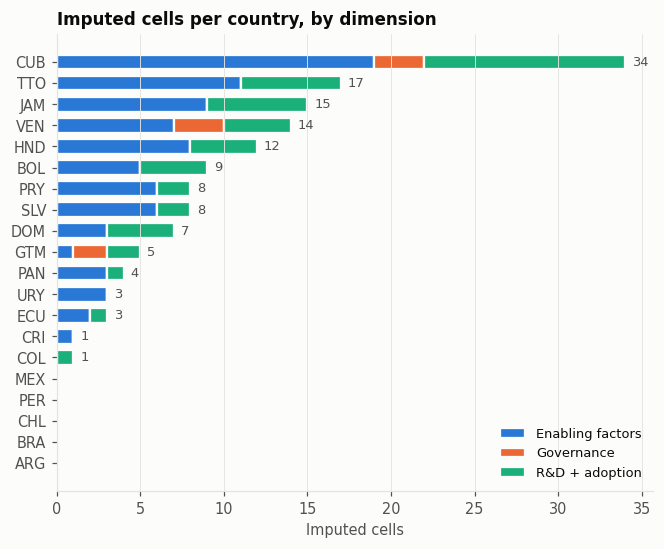

dim_code,FH,GOB,IDA,total,share_of_row
country,,,,,
Cuba,19,3,12,34,0.270
Trinidad y Tobago,11,0,6,17,0.135
Jamaica,9,0,6,15,0.119
Venezuela,7,3,4,14,0.111
Honduras,8,0,4,12,0.095
Bolivia,5,0,4,9,0.071
El Salvador,6,0,2,8,0.063
Paraguay,6,0,2,8,0.063
República Dominicana,3,0,4,7,0.056


In [5]:
fig = PL.missing_by_dimension(masked, codebook); PL.save(fig, "01_missing_by_country_dimension"); plt.show()

per_country = masked.isna().groupby(codebook["dim_code"]).sum().T
per_country["total"] = per_country.sum(axis=1)
per_country["share_of_row"] = per_country["total"] / len(masked)
per_country = per_country.sort_values("total", ascending=False)
per_country.to_csv(D.RESULTS / "missingness_by_country.csv")
per_country

In [6]:
worst = codebook.sort_values("n_imputed", ascending=False).query("n_imputed > 0")
worst[["subindicador", "n_imputed", "imputed_countries"]].head(15)

,subindicador,n_imputed,imputed_countries
code,,,
IDA.IDI.07,Entorno Emprendedor,9,"BOL, COL, CUB, HND, JAM, PAN, PRY, DOM, TTO"
FH.INF.22,Procesamiento y Almacenamiento de Datos (Nube),8,"CUB, SLV, GTM, JAM, PAN, PRY, TTO, VEN"
IDA.ADO.02,Fabricación de Tecnología Mediana y Alta,8,"CUB, SLV, GTM, HND, JAM, DOM, TTO, VEN"
IDA.ADO.03,Proporción del Valor Añadido de Fabricación de Tecnología Mediana y Alta en el Valor A...,8,"CUB, SLV, GTM, HND, JAM, DOM, TTO, VEN"
FH.INF.15,Asequibilidad de Teléfono Inteligente,8,"BOL, CRI, CUB, SLV, HND, JAM, PAN, TTO"
FH.INF.16,Asequibilidad de Computador,7,"BOL, CUB, HND, JAM, PAN, DOM, TTO"
IDA.ADO.10,Usuarios Activos de IAGen,6,"BOL, CUB, HND, JAM, PRY, TTO"
FH.TAL.02,Educación Temprana en Ciencias Niñas y Adolescentes (Puntaje Promedio),6,"BOL, CUB, ECU, HND, TTO, VEN"
FH.TAL.01,Educación Temprana en Ciencias (Puntaje Promedio),6,"BOL, CUB, ECU, HND, TTO, VEN"


## Are the gaps random?

If the countries with gaps also score low on what *is* observed, the gaps are not random: a real-data-only analysis
leaves out exactly the hard cases, and the imputation has to extrapolate to them. We compare each country's mean
z-score on the 86 complete subindicators with its number of imputed cells.

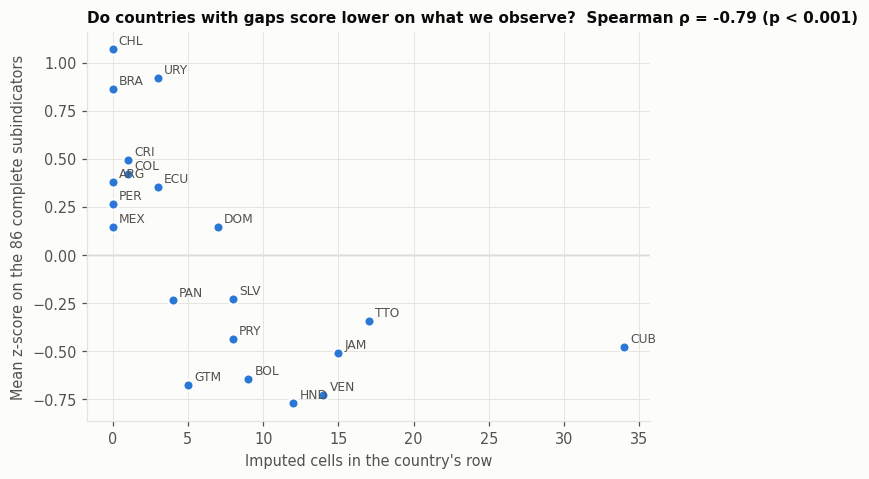

In [7]:
level = PC.standardize(A).mean(axis=1)
n_imp = D.imputed_per_country(masked)
rho, pval = spearmanr(n_imp, level.loc[n_imp.index])
fig = PL.level_vs_missing(level, n_imp, rho, pval); PL.save(fig, "01_level_vs_missing"); plt.show()
pd.DataFrame({"mean_z_complete": level, "n_imputed": n_imp}).sort_values("n_imputed", ascending=False).to_csv(
    D.RESULTS / "level_vs_missing.csv")

## Reading the results

* **141 cells (5.6%) are imputed.** 86 of the 126 subindicators are complete for all 20 countries; these form **A-full**.
  Five countries have no gaps (ARG, BRA, CHL, MEX, PER). Cuba has 34 (27% of its row), then TTO 17, JAM 15, VEN 14.
* **The gaps sit in FH (84 cells) and IDA (49); governance has 8.** A therefore leans towards governance:
  34 of its 86 subindicators (40%), against 37 of 126 (29%) in I.
* **The gaps are not random.** Countries with more imputed cells score lower on the subindicators that *are* observed
  (Spearman ρ = −0.79). The missing information belongs to the lower-scoring countries. A leaves it out;
  I fills it with values predicted partly from GDP, population and growth. Neither is neutral, which is why both are analysed.
* **English proficiency for JAM and TTO** is empty in `bruto` and was set to 100 by hand in `final` (English-speaking countries).
  It counts as imputed here, so it is absent from A and present in I.